# Proyecto 7 - Explorando factores de comportamiento en NovaRetail+


NovaRetail+ es una plataforma de comercio electrónico en Latinoamérica con millones de usuarios.

Para el cierre de 2024, el equipo de **Crecimiento y retención** tiene como objetivo responder:

**¿Qué factores del comportamiento del cliente están más fuertemente asociados con el ingreso anual generado?**

> Este proyecto es un análisis **correlacional** (exploratorio).  
> **Correlación ≠ causalidad.**

## Sección 1 - Cargar y explorar el dataset

En esta sección validamos:
- que el dataset cargue correctamente
- tipos de datos
- valores faltantes / rangos generales

Antes de correlacionar, primero entendemos el “terreno”.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pointbiserialr
from scipy.stats import chi2_contingency



### Cargar Dataset

In [2]:
# Cargar el dataset y explorar datos
df = pd.read_csv('/datasets/novaretail_comportamiento_clientes_2024.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  float64
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(5), int64(4), object(3)
memory usage: 1.4+ MB


#### Descripción del conjunto de datos

El dataset contiene las siguientes columnas:

- `id_cliente` — Identificador único del cliente.
- `edad` — Edad del cliente.
- `nivel_ingreso` — Ingreso anual estimado del cliente.
- `visitas_mes` — Número de visitas a la aplicación o sitio web durante el mes.
- `compras_mes` — Número de compras realizadas en el mes.
- `gasto_publicidad_dirigida` — Gasto en anuncios asignado al usuario.
- `satisfaccion` — Calificación de satisfacción del cliente en una escala del 1 al 5.
- `miembro_premium` — Indica si el cliente tiene suscripción premium (1) o no (0).
- `abandono` — Indica si el cliente abandonó la plataforma (1) o no (0).
- `tipo_dispositivo` — Tipo de dispositivo utilizado por el cliente (móvil, escritorio o tablet).
- `region` — Región geográfica del cliente (norte, sur, oeste o este).
- `ingreso_anual` — Ingreso anual generado por el cliente para la empresa.

La métrica principal de análisis es `ingreso_anual`, utilizada para evaluar el impacto económico de los clientes.


In [3]:
df.head(5)


,id_cliente,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,tipo_dispositivo,region,ingreso_anual
0,CL-100000,44.0,28565.77,9,1,31.36,3.9,0,0,móvil,norte,23.22
1,CL-100001,36.0,29673.44,11,3,24.66,3.7,0,0,tablet,sur,93.47
2,CL-100002,46.0,30642.95,9,0,0.00,2.9,0,0,móvil,este,0.00
3,CL-100003,56.0,39468.61,8,0,6.81,3.1,0,0,móvil,este,0.00
4,CL-100004,35.0,22527.83,9,2,26.49,2.3,0,0,móvil,sur,33.76


## Sección 2 - Preparar datos y documentar supuestos

### Exploración y Limpieza

#### Exploración inicial de los datos
El conjunto de datos contiene **15,000 registros** y **12 columnas**, sin valores nulos.

**Variables numéricas**  
Se identifican las siguientes columnas numéricas:
- `edad`
- 

La mayoría de estas variables presentan tipos de datos adecuados.  
La columna ... .


**Variables binarias**  
Las siguientes columnas representan variables binarias:
- `miembro_premium`
- `abandono`

Ambas están codificadas como 0 y 1, **no requieren transformación adicional**.

**Variables categóricas**  
Se identifican las siguientes columnas categóricas:
- `id_cliente`
- `tipo_dispositivo`
- `region`

Estas variables están correctamente definidas y no requieren transformación adicional.

In [4]:
# Corregir el tipo de dato
df['edad'] = df['edad'].astype(int)

In [5]:
# verificar cambios
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  int64  
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(4), int64(5), object(3)
memory usage: 1.4+ MB


#### Explorar variables numéricas

In [6]:
# Estadísticas descriptivas de variables numéricas
df.describe()

,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,ingreso_anual
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,38.262400,30019.704782,10.029000,1.206467,20.149301,3.603693,0.139267,0.150733,36.594180
std,11.492378,9833.166305,3.158189,1.105284,10.880724,0.685300,0.346236,0.357801,34.484888
min,18.000000,8000.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
25%,30.000000,23127.097500,8.000000,0.000000,12.310000,3.100000,0.000000,0.000000,0.000000
50%,38.000000,30023.745000,10.000000,1.000000,19.730000,3.600000,0.000000,0.000000,30.705000
75%,46.000000,36768.440000,12.000000,2.000000,27.292500,4.100000,0.000000,0.000000,58.220000
max,75.000000,74790.840000,25.000000,8.000000,75.510000,5.000000,1.000000,1.000000,244.690000


✍️

Diagnóstico inicial de variables numéricas

- `edad` — la media y la mediana son muy similares, lo que sugiere una distribución relativamente equilibrada. No se observa una diferencia importante entre ambas medidas.
- 'nivel de ingresos' - los ingresos presentan una dispersión considerable. Sin embargo, la media y la mediana son prácticamente iguales, lo que sugiere que no existe un sesgo fuerte en la distribución general.
- 'visitas por mes'- el comportamiento está bastante centrado alrededor de 10 visitas mensuales. La media y la mediana coinciden casi exactamente, lo que indica una distribución aparentemente equilibrada.
- 'compras_mes'- la mayoría de los clientes realiza pocas compras al mes. El percentil 75 es de 2 compras, lo que indica que el 75 % de los registros realiza como máximo dos compras mensuales.
- 'gasto_publicidad_dirigida'- existe una dispersión considerable en esta variable. El máximo está bastante alejado de la mediana, por lo que conviene investigar si existen valores extremos o clientes con una exposición especialmente alta.
- 'satisfaccion'- los clientes presentan un nivel de satisfacción promedio moderado-alto. La cercanía entre la media y la mediana sugiere que los resultados están relativamente centrados. Sería interesante analizar qué factores influyen en las puntuaciones más bajas.
- 'miembro_premium'-es una variable binaria (0 y 1). La mediana de cero indica que al menos la mitad de los clientes no pertenece al programa premium. aproximadamente el 13,93 % pertenece a este segmento
- 'abondono'- también es una variable binaria. Esto sugiere que aproximadamente el 15,07 % de los clientes abandonó el servicio, mientras que el resto permanece. Es una variable importante para estudiar la retención de clientes.
- 'ingreso_anual'- existe una diferencia importante entre la media y la mediana. La media superior a la mediana sugiere un posible sesgo hacia la derecha, posiblemente provocado por clientes con ingresos anuales muy elevados. También es importante investigar los valores iguales a cero.

#### Explorar variables binarias

In [7]:
# Verificar que cada columna tenga únicamente dos valores posibles
df['miembro_premium'].value_counts()


0    12911
1     2089
Name: miembro_premium, dtype: int64

In [8]:
df['abandono'].unique()

array([0, 1])

✍️ 

Diagnóstico inicial de variables binarias

- `miembro_premium` — en la columna binaria de miembros y no miembros premium, se aprecia solamente dos datos (1, 0) dado que solo se observan dos valores posibles
- `abandono` —  En la columna binaria de abandono con .unique()  tambien solo se observan dos valores unicos 1,0 sin ningun dato adicional que se deba cambiar o corregir

#### Explorar variables categóricas

In [9]:
# Verificar el número de valores únicos por variable categórica
categoricas = ['tipo_dispositivo', 'region']

for cat in categoricas:
    print(df[cat].unique())

['móvil' 'tablet' 'escritorio']
['norte' 'sur' 'este' 'oeste']


In [10]:
# Explorar variables categóricas y cómo se distribuyen
categoricas = ['tipo_dispositivo', 'region']

for cat in categoricas:
    print(df[cat].value_counts())

móvil         9818
escritorio    3720
tablet        1462
Name: tipo_dispositivo, dtype: int64
norte    4395
oeste    3810
sur      3726
este     3069
Name: region, dtype: int64


✍️

Diagnóstico inicial de variables categóricas

- `tipo_dispositivo` — En la columna dispositivo se hayan valores unicos como movil, tablet, escritorio, sin ningun dato faltante o NA, con value_counts, la cantidad de veces por dispositivo, sin errores
- 'region' - En la columna de regiones ocurre lo mismo valores unicos 4, norte, sur, este, oeste, sin errores, y contando la cantidad de veces por regio 

### Supuestos

- El análisis se realiza utilizando **todo el conjunto de datos disponible**.
- Los datos no presentan errores y están correctamente tipificados.
- Se utilizan distintos coeficientes según el tipo de variable:
  - **Pearson** asume relaciones lineales entre variables numéricas.
  - **Spearman** evalúa relaciones monótonas y no requiere normalidad.
  - **Punto biserial** se usa para relaciones numérica–binaria.
  - **Cramér (V)** se usa para asociaciones entre variables categóricas.

**Supuesto central:**  
Este análisis identifica relaciones entre variables o segmentos, pero no prueba causalidad.

## Sección 3 - Visualización de relaciones

Observamos cómo se relacionan las variables numéricas.

### Heatmap

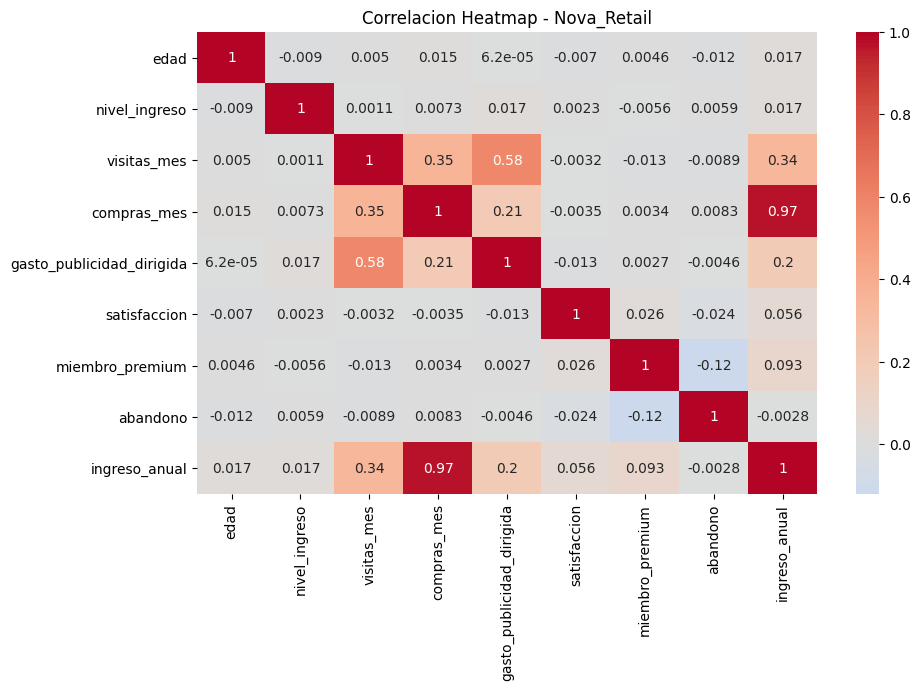

In [11]:
# Visualizar la matriz de correlación para identificar relaciones
corr = df.corr()

plt.figure(figsize=(10, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', center=0)
plt.title('Correlacion Heatmap - Nova_Retail')
plt.show()

✍️ 

Observaciones generales (Heatmap)  
- Se observa la mayoria de las celdas estan entre -0.03 y 0.03, no hay relacion lineal. solo hay un nucleo de variables que si se relacionan: visitas_mes, compras_mes, gasto_publicitario_dirigido e ingreso_anual.
- gasto publicidad y visitas_mes tienen la correlacion moderada (0.58) la publicidad parece atraer trafico
- visitas_mes y compras_mes tienen 0.35 mas visitas se relaciona con mas compras pero no es una correlacion muy fuerte.
- Gasto_publicidad y compra_mes tiene solo 0.21 el efecto de la publicidad sobre las compras parece pasar atraves de las visitas, es una hipotesis, sin demostrar


Observaciones respecto a `ingreso_anual`  
- Presenta 0.97 con compras_mes es bastante alto casi perfecto
- ingreso anual con nivel_ingreso su relacion es casi nula (0.017), esperaria que fueran parecidas, pero esta bastante alejado de una relacion moderada
  


### Scatterplot general

Con base en los resultados del análisis de correlación, evalúa si es necesario generar un *scatterplot* general.

- **Si decides incluirlo**:
  - Genera el gráfico.
  - Describe brevemente qué patrones o tendencias observas.

- **Si decides no incluirlo**:
  - Explica por qué.

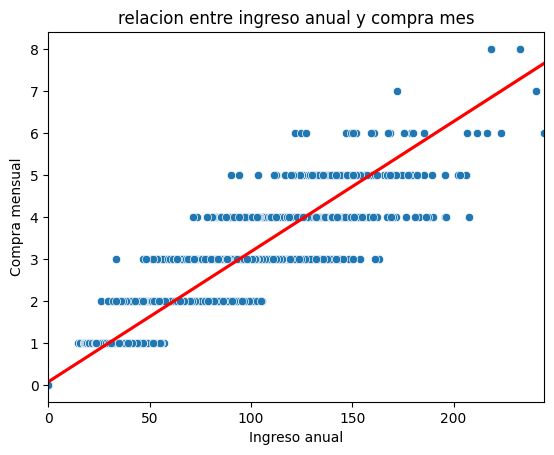

In [12]:
sns.scatterplot(data=df, x='ingreso_anual', y='compras_mes')
sns.regplot(data=df, x='ingreso_anual', y='compras_mes', scatter=False, color='red')

plt.title('relacion entre ingreso anual y compra mes')
plt.xlabel('Ingreso anual')
plt.ylabel('Compra mensual')
plt.show()




In [13]:
**Descripcion general**:
La tendencia es positiva a mayor ingreso anual, mas compras mensuales, la recta intercepta
cerca de 0 con ingreso casi nulo se espera casi 0 compras, lo cual es logico.
la coherencia_anual encaja con una relacion asi de marcada. la nube sigue la recta de cerca, aunque
se nota algo de dispersion horizontal.
hay unos puntos aislados con 3 compras y un ingreso de ~33, muy a la izquierda de su fila. tambien hay puntos con 4 y 5 compras en el extremo derecho(205).
que parecen alargar un poco las filas.
En las filas centrales los puntos se apilan tanto que no se logra apreciar cuantos hay realmente.

SyntaxError: invalid syntax (1647735360.py, line 1)

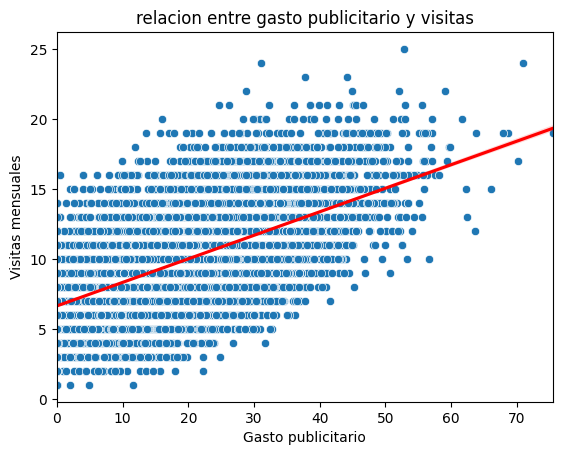

In [13]:
sns.scatterplot(data=df, x='gasto_publicidad_dirigida', y='visitas_mes')
sns.regplot(data=df, x='gasto_publicidad_dirigida', y='visitas_mes', scatter=False, color='red')

plt.title('relacion entre gasto publicitario y visitas')
plt.xlabel('Gasto publicitario')
plt.ylabel('Visitas mensuales')
plt.show()

In [ ]:
**Descripcion General**:
El grafico muestra la relacion entre gasto publicitario (eje x, de 0 a 75) y visitas mensuales (eje Y, 0 a 25) con una linea de regresion lienal en rojo, 
tendencia positiva y lineal gasto publicitario, mas visitas. la recta sube a 7 visitas cuando el gasto es 0 a 19 y 20 visitas cuando el gasto ronda en 75
Coherencia con el heatmap la correlacion de 0.58 que se observo antes encaja con esta nube. Es una relacion moderada, no fuerte


### Scatterplot para pares clave

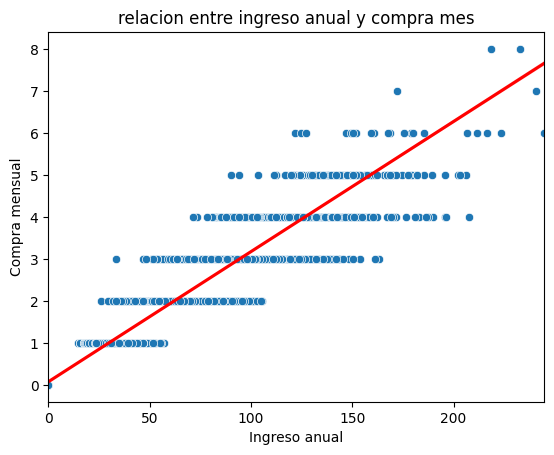

In [14]:
# Visualizar pares de variables con relaciones moderadas o fuertes
sns.scatterplot(data=df, x='ingreso_anual', y='compras_mes')
sns.regplot(data=df, x='ingreso_anual', y='compras_mes', scatter=False, color='red')

plt.title('relacion entre ingreso anual y compra mes')
plt.xlabel('Ingreso anual')
plt.ylabel('Compra mensual')
plt.show()

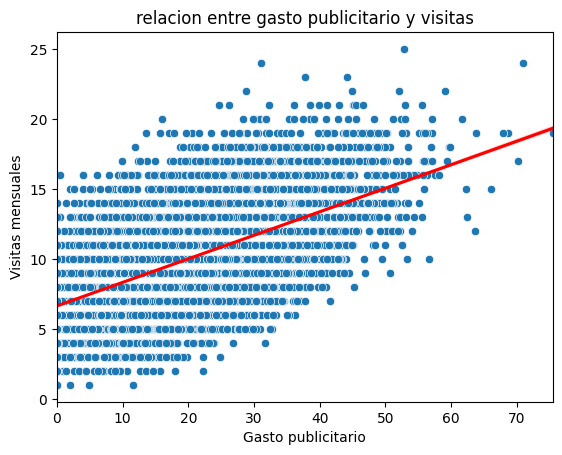

In [15]:
sns.scatterplot(data=df, x='gasto_publicidad_dirigida', y='visitas_mes')
sns.regplot(data=df, x='gasto_publicidad_dirigida', y='visitas_mes', scatter=False, color='red')

plt.title('relacion entre gasto publicitario y visitas')
plt.xlabel('Gasto publicitario')
plt.ylabel('Visitas mensuales')
plt.show()

✍️ dirección (positiva o negativa), dispersión (alta, media, baja), presencia de outliers y posible colinealidad.


Observaciones iniciales (Scatterplot)

**ingreso anual vs compras mensuales**
- Dirección positiva, la recta roja sube de izquierda a derecha:a mayor ingreso anual, mas compras al mes. Es coherente con la correlacion de 0.97 del heatmap, no hay ningun punto que se aleje drasticamente de la recta, asi que no veo outliers que distorsionen el ajuste.
- 

**gasto publicitario vs visitas**
- Dirección positiva la recta roja sube de izquierda a derecha a mas gasto piblicitario, mas visitas. la nube es ancha y los puntos se alejan mucho de la recta. con un mismo gasto(ejemplo 30) las visitas van de 3 a 24.Es una relacion moderada no fuerte de (0.58) el gasto explica solo el 34% de la variacion en visitas. El resto depende de otros factores diferentes
- a partir de gasto 50 hay muy pocos puntos, asi que la recta es menos confiable ahi, puntos que tienen mas influencia sobre la pendiente
- 

## Sección 4 - Coeficientes de correlación y evidencia numérica

En esta sección, se reportan coeficientes que respaldan los patrones
observados visualmente, utilizando el método adecuado según el tipo
de variables.

### Pearson / Spearman

In [16]:
# Calcular correlación entre variables relevantes
df['ingreso_anual'].corr(df['compras_mes'],method='pearson')

0.9671485435708566

In [17]:
# Calcular correlación entre variables relevantes
df['gasto_publicidad_dirigida'].corr(df['visitas_mes'], method='spearman')

0.5592673242622609

In [18]:
df['gasto_publicidad_dirigida'].corr(df['visitas_mes'], method='pearson')

0.5789472719412827

✍️


Observaciones de correlación

**ingreso_anual vs compras_mes**
- correlacion positiva cuando aumenta el ingreso anual, tambien tiende a aumentar la cantidad de compras_mensuales. Es muy fuerte (0.96), existe una asociacion lineal bastante elevada entre ambas variables.
  
  
**Gasto_publicidad_dirigido vs visitas_mes**
- Correlación positiva a mayor gasto publicitario, generalmente se observa un aumento en las visitas mensuales. Con una magnitud moderada (pearson 0.57 y spearman 0.55), no hay evidencia de una correlacion elevada entre estas dos variables.
- 

### Punto-biserial

In [19]:
# Calcular correlación entre variables relevantes
pointbiserialr(df['miembro_premium'], df['ingreso_anual'])


SignificanceResult(statistic=0.0930994396198015, pvalue=3.0943076155242597e-30)

✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.   
Incluye qué ves: dirección (positiva o negativa), magnitud (alta, media, baja).

Observaciones Punto-biserial

**miembro_premium vs ingreso_anual**
- existe una relacion bi serial postiva muy debil los usuarios premium tienden a tener ingresos anuales un poco mas alto que los miembros no premium, con una magnitud baja, casi nula, en la practica, ser miembro premium explica solo cerca del 0.9% de la variacion del ingreso anual 


### V de Cramér

In [21]:
# Función para calcular V de Cramér
def cramer_v(df, tipo_dispositivo, region):
    tabla = pd.crosstab(df[tipo_dispositivo], df[region])
    chi2, p_value, dof, expected = chi2_contingency(tabla)

    n = tabla.values.sum()
    coef_v = np.sqrt(chi2 / (n* (min(tabla.shape) -1)))

    print(f"v de cramer ({tipo_dispositivo} vs {region}):", coef_v)
    



In [22]:
cramer_v(df, 'tipo_dispositivo', 'region')

v de cramer (tipo_dispositivo vs region): 0.012378338407739397


✍️ **Comentario**:
realizando v de cramer en las variables categoricas region y tipo_dispositivo, se da una correlacion muy nula de 0.012, dato q no tienen relacion esta dos variables
independencia practica de la region geografica no parece estar asociado con el tipo de dispositivo utilizado por los usuarios



## Sección 5 - Interpretación de resultados para el negocio

Cada hallazgo  debe incluir:
1) Evidencia visual (si aplica)
2) Evidencia numérica  
3) Interpretación (no causal)  
4) No podemos afirmar
5) Implicación de negocio

---

✍️

)### Hallazgo 1 — 
  ingreso_anual - compras_mes
**Evidencia numérica:** correlacion 0.97, las compras y el ingreso comparten cerca del 94% de su variacion lineal, 0.03 compras mensual mas por cada unidad de ingreso anual, es decir una compra adicional por cada 30 unidades de ingreso
La dispersion es baja a media y aumenta en los niveles medios y altos de compras, en 1 compra el rango de ingreso es de 40 unidades, y en 4 a 5 comrpas llega a 120. Se realizo metodo Coeficientes de correlación y evidencia numérica de  (0.967) utilizando solo el metodo pearson, ya que teniamos una relacion lineal sin datos elevado o posibles outliers 

**Interpretación**  Las dos variables se mueven casi a la par, los clientes con mas compras mensuales tienden a tener un ingreso anual mas alto, y viceversa. la relacion es tan fuerte que podrian estar midiendo casi lo mismo, el grafico no permite decir cual influye en cual.


**No podemos afirmar**  las compras generan el ingreso, ni al reves (r=0.97). si ingreso_anual se calculo a partir de las compras, la relacion seria casi mecanica y no un hallazgo
no se puede afirmar que ser miembro premium reduzca el abandono r=0.12. quienes ya son leales podrian ser quienes se hacen premium.


**Implicación de negocio**  Las compras mensuales sirven como indicar rapido del ingreso anual del cliente, util para segmentar y priorizar, antes de usarlas como predictora, hay que verificar como se contruyo ingreso anual, para evitar redundancia o fuga de informacion


### Hallazgo 2 — 

  
**Evidencia numérica:** Correlacion r=0.58 el gasto se asocia con aproximadamente un tercio de la variacion de las visitas.
7 visitas con gasto 0. Pendiente apoximadamente: 0.17 visitas mas por unidad de gasto(17 visitas por cada 100)
dispersion es alta con gasto de 30, las visitas van de 3 a 24.
varios puntos con gastos de 60 a 65 quedan por debajo de al recta
se realizo Coeficientes de correlación y evidencia numérica con los metodos de pearson y spearman como resultado en pearson (0.559) y spearman (0.578) sin alejarse mucho de el heatmap.

**Interpretación**  los periodos o registros con mayor gasto publicitario tienden a registrar mas visitas, pero la asociacion es moderada y ruidosa. Con el mismo gasto se observan resultados muy distintos, lo que indica que no se puede afirmar que el gasto produzca las visitas


**No podemos afirmar**  que el gasto en publicidad cause mas visitas(r0.58). solo vmos que suben juntos. podria haber una tercera variable(temporada, campañas, pormociones) que impulsan ambos, o que la empresa inviertan mas justo cuando espera mas trafico.


**Implicación de negocio**  La publicidad parece ir acompañada de mas trafico pero no garantiza un resultado, podria ser variable el resultado.
Existe un nivel base de visitas (7) que no depende del gasto, asi que no todo el trafico se atribuye a la publicidad.
En los gastos mayores a 50 hay pocos datos y algunos puntos por debajo de la tendencia, lo que justifica revisar si hay rendimientos decrecientes antes de aumentar el presupuesto en esa zona.
conviene analizar otros factores como canal, campaña, temporada).


## Sección 6 - Limitaciones y próximos pasos

✍️ 

### **Limitaciones**
- Correlación ≠ causalidad
- 

### **Próximos pasos** 

Probar segmentación adicional
- rengos de edad:
  Si la publicidad funciona distinto según la edad, aunque el promedio no muestre relación
- Rangos de nivel_ingreso:
  Si existen patrones de compra distintos por nivel, pese a la correlación casi nula

  Nivel de gasto publicitario (bajo, medio, alto):
  Si hay rendimientos decrecientes en los gastos altos

- Nivel de satisfaccion:
  Si hay un umbral por debajo del cual aumenta el abandono